In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
import os
os.chdir('E:/Machine_Learning/Cases/Image_Segmentation')

In [4]:
image = pd.read_csv('Image_Segmentation.csv')
image.head()

,Class,region.centroid.col,region.centroid.row,region.pixel.count,short.line.density.5,short.line.density.2,vedge.mean,vegde.sd,hedge.mean,hedge.sd,intensity.mean,rawred.mean,rawblue.mean,rawgreen.mean,exred.mean,exblue.mean,exgreen.mean,value.mean,saturation.mean,hue-mean
0,BRICKFACE,188,133,9,0.0,0.0,0.333333,0.266667,0.500000,0.077778,6.666666,8.333334,7.777778,3.888889,5.000000,3.333333,-8.333333,8.444445,0.538580,-0.924817
1,BRICKFACE,105,139,9,0.0,0.0,0.277778,0.107407,0.833333,0.522222,6.111111,7.555555,7.222222,3.555556,4.333334,3.333333,-7.666666,7.555555,0.532628,-0.965946
2,BRICKFACE,34,137,9,0.0,0.0,0.500000,0.166667,1.111111,0.474074,5.851852,7.777778,6.444445,3.333333,5.777778,1.777778,-7.555555,7.777778,0.573633,-0.744272
3,BRICKFACE,39,111,9,0.0,0.0,0.722222,0.374074,0.888889,0.429629,6.037037,7.000000,7.666666,3.444444,2.888889,4.888889,-7.777778,7.888889,0.562919,-1.175773
4,BRICKFACE,16,128,9,0.0,0.0,0.500000,0.077778,0.666667,0.311111,5.555555,6.888889,6.666666,3.111111,4.000000,3.333333,-7.333334,7.111111,0.561508,-0.985811


In [10]:
X,y = image.drop('Class',axis = 1),image['Class']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=26,stratify=y)
lr = LogisticRegression()
lr.fit(X_train,y_train)
y_pred = lr.predict(X_test)
acc= accuracy_score(y_test,y_pred)
acc

C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.873015873015873

In [16]:
solvers = ['lbfgs', 'newton-cg', 'newton-cholesky', 'sag', 'saga']
scores =[]
for s in solvers:
    lr = LogisticRegression(solver=s)
    lr.fit(X_train,y_train)
    y_pred = lr.predict(X_test)
    acc= accuracy_score(y_test,y_pred)
    scores.append([s,acc])
data = pd.DataFrame(data = scores,columns=['solver','Accuracy'])
data.sort_values(by= 'Accuracy',ascending=False)

C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_

,solver,Accuracy
1,newton-cg,0.920635
2,newton-cholesky,0.904762
0,lbfgs,0.873016
3,sag,0.841270
4,saga,0.793651


In [19]:
Cs = np.linspace(0.001,10,20)
solvers = ['lbfgs', 'newton-cg', 'newton-cholesky', 'sag', 'saga']
scores =[]
for s in solvers:
    for c in Cs:
        lr = LogisticRegression(solver=s,C=c)
        lr.fit(X_train,y_train)
        y_pred = lr.predict(X_test)
        acc= accuracy_score(y_test,y_pred)
        scores.append([s,c,acc])
data = pd.DataFrame(data = scores,columns=['solver','C','Accuracy'])
data.sort_values(by= 'Accuracy',ascending=False).head(10)

C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as s

,solver,C,Accuracy
34,newton-cg,7.368684,0.920635
25,newton-cg,2.632316,0.920635
27,newton-cg,3.684842,0.920635
28,newton-cg,4.211105,0.920635
24,newton-cg,2.106053,0.920635
23,newton-cg,1.579789,0.920635
22,newton-cg,1.053526,0.920635
26,newton-cg,3.158579,0.920635
32,newton-cg,6.316158,0.920635
31,newton-cg,5.789895,0.920635


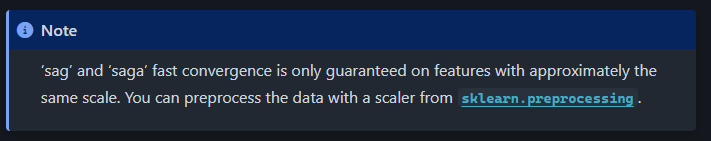

We scale features and then use sag and saga for better accuracy